# 2. Probability and sampling

Everything in hypothesis testing rests on one idea: a statistic computed from a sample has its own distribution, and we can describe it. Here I show that with real data instead of formulas.

I treat the 17,379 hourly bike counts as a "population" I can sample from. It is right skewed, which makes it a fair test for the central limit theorem.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src import SEED
from src.data import load_bank, load_bike_day, load_bike_hour
from src.plotting import INK_2, PALETTE, save, set_style
from src.stats_utils import bootstrap_ci

set_style()
rng = np.random.default_rng(SEED)

pop = load_bike_hour()["cnt"].to_numpy()
mu, sigma = pop.mean(), pop.std()
print(f"population: N={len(pop):,}  mean={mu:.2f}  sd={sigma:.2f}  skew={stats.skew(pop):.3f}")

population: N=17,379  mean=189.46  sd=181.38  skew=1.277


## Sampling distribution of the mean and the CLT

For each sample size n I draw 10,000 samples, take the mean of each, and look at how those means are spread. The CLT says the spread should approach a normal curve with standard deviation sigma divided by the square root of n, whatever shape the population has.

In [2]:
sizes = [2, 5, 30, 100]
reps = 10_000
means = {n: rng.choice(pop, size=(reps, n), replace=True).mean(axis=1) for n in sizes}

summary = pd.DataFrame({
    "n": sizes,
    "sd of sample means": [means[n].std() for n in sizes],
    "sigma / sqrt(n)": [sigma / np.sqrt(n) for n in sizes],
    "skew of sample means": [stats.skew(means[n]) for n in sizes],
})
summary

,n,sd of sample means,sigma / sqrt(n),skew of sample means
0,2,126.095213,128.256711,0.910372
1,5,79.924184,81.116667,0.518629
2,30,33.293340,33.115740,0.202951
3,100,18.017054,18.138238,0.115769


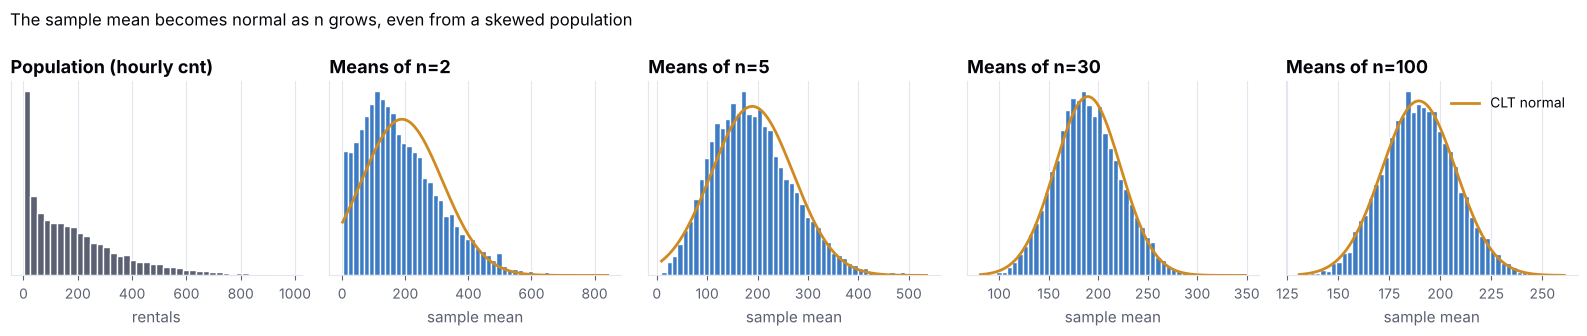

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
axes[0].hist(pop, bins=40, color=INK_2, edgecolor="white")
axes[0].set(title="Population (hourly cnt)", xlabel="rentals", yticks=[])
for ax, n in zip(axes[1:], sizes):
    m = means[n]
    ax.hist(m, bins=50, density=True, color=PALETTE[0], edgecolor="white")
    xs = np.linspace(m.min(), m.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sigma / np.sqrt(n)), color=PALETTE[1], label="CLT normal")
    ax.set(title=f"Means of n={n}", xlabel="sample mean", yticks=[])
axes[-1].legend(loc="upper right")
fig.suptitle("The sample mean becomes normal as n grows, even from a skewed population", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "clt.png");

At n=2 the sample means are still skewed. By n=30 the orange normal curve fits well, and the measured spread matches sigma over root n closely at every n. That match is what makes a standard error a sensible thing to compute.

## Confidence intervals, and what "95%" means

A 95% interval procedure should cover the true value in 95% of repeated samples. Since I know the population mean here, I can check that directly. I draw 2,000 samples of n=50, build a t interval from each, and count how many contain the true mean.

In [4]:
n, reps = 50, 2_000
samples = rng.choice(pop, size=(reps, n), replace=True)
xbar = samples.mean(axis=1)
se = samples.std(axis=1, ddof=1) / np.sqrt(n)
tcrit = stats.t.ppf(0.975, df=n - 1)
covered = (xbar - tcrit * se <= mu) & (mu <= xbar + tcrit * se)
print(f"t interval coverage at n={n}: {covered.mean():.3f}  (target 0.95)")

t interval coverage at n=50: 0.953  (target 0.95)


Close to 95%, a little under, because the population is skewed and n=50 is not huge. That small shortfall is normal and worth knowing about.

## Bootstrap confidence intervals

The bootstrap resamples the data I have to approximate the sampling distribution of any statistic, including ones with no simple formula, like the median. First a coverage check against the known population median.

In [5]:
true_median = np.median(pop)
reps, n, n_boot = 1_000, 50, 2_000
hits = 0
for _ in range(reps):
    s = rng.choice(pop, size=n, replace=True)
    boot = np.median(s[rng.integers(0, n, size=(n_boot, n))], axis=1)
    lo, hi = np.quantile(boot, [0.025, 0.975])
    hits += lo <= true_median <= hi
print(f"population median: {true_median:.0f}")
print(f"percentile bootstrap coverage for the median at n={n}: {hits / reps:.3f}  (target 0.95)")

population median: 142
percentile bootstrap coverage for the median at n=50: 0.943  (target 0.95)


Now on a real question with the real sample. What is the median number of daily rentals, and how sure am I?

median daily rentals: 4548, 95% bootstrap CI [4362, 4669]


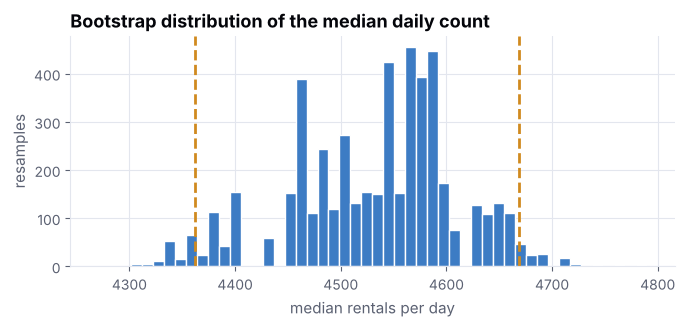

In [6]:
day = load_bike_day()
lo, hi, boots = bootstrap_ci(day["cnt"], stat=np.median, n_boot=5_000, seed=SEED)
print(f"median daily rentals: {day['cnt'].median():.0f}, 95% bootstrap CI [{lo:.0f}, {hi:.0f}]")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(boots, bins=50, color=PALETTE[0], edgecolor="white")
for v in (lo, hi):
    ax.axvline(v, color=PALETTE[1], linestyle="--")
ax.set(title="Bootstrap distribution of the median daily count", xlabel="median rentals per day", ylabel="resamples")
fig.tight_layout()

A caveat I want to be honest about: the bootstrap assumes the observations are independent. Bike days are not. A warm week follows a warm week. So this interval is probably a bit too narrow. A block bootstrap would be the fix if this number mattered for a decision.

### Bootstrap for a difference in proportions

Does a client who was contacted by mobile phone subscribe more often than one reached on a landline? I bootstrap the difference in rates and compare it to the textbook normal approximation.

In [7]:
bank = load_bank()
cell = bank.loc[bank["contact"] == "cellular", "subscribed"].to_numpy()
tel = bank.loc[bank["contact"] == "telephone", "subscribed"].to_numpy()

n_boot = 5_000
diff_boot = (rng.choice(cell, size=(n_boot, len(cell))).mean(axis=1)
             - rng.choice(tel, size=(n_boot, len(tel))).mean(axis=1))
b_lo, b_hi = np.quantile(diff_boot, [0.025, 0.975])

p1, p2 = cell.mean(), tel.mean()
se = np.sqrt(p1 * (1 - p1) / len(cell) + p2 * (1 - p2) / len(tel))
diff = p1 - p2
print(f"cellular {p1:.4f}  telephone {p2:.4f}  difference {diff:.4f}")
print(f"bootstrap 95% CI: [{b_lo:.4f}, {b_hi:.4f}]")
print(f"normal-approx 95% CI: [{diff - 1.96 * se:.4f}, {diff + 1.96 * se:.4f}]")

cellular 0.1474  telephone 0.0523  difference 0.0951
bootstrap 95% CI: [0.0895, 0.1007]
normal-approx 95% CI: [0.0895, 0.1006]


With tens of thousands of rows the two methods agree to three decimals. The bootstrap earns its keep with small samples and awkward statistics, not here. The gap itself is large, but this is observational data: landline clients may differ in age and in when they were called, so I do not read it as "mobile calls cause subscriptions".